In [2]:
import os
import glob
import xarray as xr
import rioxarray
import pandas as pd

folder_path = "mystorage/NO2_Mensual"

file_paths = sorted(glob.glob(os.path.join(folder_path, "NO2_*.tiff")))

data_arrays = []
time_coords = []

print(f"Construyendo el Data Cube a partir de {len(file_paths)} matrices...")

for file_path in file_paths:
    filename = os.path.basename(file_path)
    
    parts = filename.replace(".tiff", "").split("_")
    year = int(parts[1])
    month = int(parts[2])
    
    date = pd.Timestamp(year=year, month=month, day=1)
    time_coords.append(date)
    
    da_raw = rioxarray.open_rasterio(file_path)
    
    no2_band = da_raw.sel(band=1, drop=True)
    mask_band = da_raw.sel(band=2, drop=True)
    
    da_clean = no2_band.where(mask_band == 1)
    
    data_arrays.append(da_clean)


no2_cube = xr.concat(data_arrays, dim=pd.Index(time_coords, name="time"))

no2_cube.name = "NO2"
no2_cube.attrs["units"] = "mol/m²"
no2_cube.attrs["long_name"] = "Densidad de Columna Vertical Troposférica de NO2"
no2_cube.rio.write_crs("EPSG:4326", inplace=True)

print("Data Cube de NO2 construido")
no2_cube

Construyendo el Data Cube a partir de 84 matrices...


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as 

Data Cube de NO2 construido


Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.
Warning 1: TIFFReadDirectory:Sum of Photometric type-related color channels and ExtraSamples doesn't match SamplesPerPixel. Defining non-color channels as ExtraSamples.


<xarray.DataArray 'NO2' (time: 84, y: 14, x: 18)> Size: 85kB
array([[[1.22185538e-05, 1.30468452e-05, 1.22126376e-05, ...,
         1.48035970e-05, 1.73182834e-05, 1.81303240e-05],
        [1.02810181e-05, 1.36016661e-05, 1.19194874e-05, ...,
         1.44655478e-05, 1.86672314e-05, 1.46575221e-05],
        [1.64251433e-05, 2.12660489e-05, 2.29670186e-05, ...,
         1.62941087e-05, 1.88721133e-05, 1.70563417e-05],
        ...,
        [           nan,            nan, 1.69674313e-05, ...,
         2.27458113e-05, 1.69225423e-05, 1.22341935e-05],
        [4.63994766e-05, 4.63994766e-05, 4.20299039e-05, ...,
         1.89509301e-05, 1.17929967e-05, 2.41630028e-06],
        [5.96286773e-05, 5.94649027e-05, 4.80789568e-05, ...,
         2.06415207e-05, 9.34186028e-06, 2.27170294e-05]],

       [[1.82992389e-05, 2.28900535e-05, 1.70777093e-05, ...,
         1.81134419e-05, 2.07064822e-05, 2.04414064e-05],
        [1.67262988e-05, 3.51652961e-05, 4.01083671e-05, ...,
         1.68062979e-05, 1.93993383e-05, 2.01381299e-05],
        [2.93717676e-05, 2.93717676e-05, 3.24663270e-05, ...,
         2.45203792e-05, 2.45203792e-05, 2.59241697e-05],
...
         2.74923659e-05, 2.57979864e-05, 2.52654663e-05],
        [7.29198655e-05, 5.36742118e-05, 4.96576540e-05, ...,
         2.53072139e-05, 2.45710307e-05, 3.01258042e-05],
        [4.59746188e-05, 3.30643816e-05, 4.75101115e-05, ...,
         2.83292593e-05, 2.48886226e-05, 3.87383116e-05]],

       [[2.47931130e-05, 2.32114708e-05, 2.14994525e-05, ...,
         2.23717816e-05, 2.25546228e-05, 2.52987593e-05],
        [2.41184316e-05, 2.36202595e-05, 2.60495981e-05, ...,
         2.45081519e-05, 2.86192808e-05, 2.35054158e-05],
        [2.83653681e-05, 2.73115493e-05, 2.93460907e-05, ...,
         3.35084660e-05, 3.20680192e-05, 3.20814288e-05],
        ...,
        [           nan, 4.35045768e-05,            nan, ...,
         2.47497719e-05, 2.01466446e-05, 1.78747850e-05],
        [5.23176168e-05, 5.23176168e-05,            nan, ...,
         2.49128025e-05, 2.39478286e-05, 2.74332233e-05],
        [3.92848087e-05, 2.34407271e-05, 1.53264245e-05, ...,
         3.25758119e-05, 2.62221820e-05, 3.01465207e-05]]],
      shape=(84, 14, 18), dtype=float32)
Coordinates:
  * time         (time) datetime64[us] 672B 2018-07-01 2018-08-01 ... 2025-06-01
  * y            (y) float64 112B 14.89 14.84 14.79 14.75 ... 14.36 14.31 14.27
  * x            (x) float64 144B -90.75 -90.72 -90.69 ... -90.29 -90.26 -90.23
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    scale_factor:            1.0
    add_offset:              0.0
    units:                   mol/m²
    long_name:               Densidad de Columna Vertical Troposférica de NO2

In [3]:
import geopandas as gpd

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson")

poligono_amg = poligono_amg.to_crs("EPSG:4326")

print("Aplicando enmascaramiento espacial al Cubo de Datos...")

no2_cube_masked = no2_cube.rio.clip(poligono_amg.geometry, poligono_amg.crs, drop=False)

print("Enmascaramiento completado")

no2_cube_masked

Aplicando enmascaramiento espacial al Cubo de Datos...
Enmascaramiento completado


<xarray.DataArray 'NO2' (time: 84, y: 14, x: 18)> Size: 85kB
array([[[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan, 2.2967019e-05, ...,
                   nan,           nan,           nan],
        ...,
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]],

       [[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan, 3.2466327e-05, ...,
                   nan,           nan,           nan],
...
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]],

       [[          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan, 2.9346091e-05, ...,
                   nan,           nan,           nan],
        ...,
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan],
        [          nan,           nan,           nan, ...,
                   nan,           nan,           nan]]],
      shape=(84, 14, 18), dtype=float32)
Coordinates:
  * time         (time) datetime64[us] 672B 2018-07-01 2018-08-01 ... 2025-06-01
  * y            (y) float64 112B 14.89 14.84 14.79 14.75 ... 14.36 14.31 14.27
  * x            (x) float64 144B -90.75 -90.72 -90.69 ... -90.29 -90.26 -90.23
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_XRESOLUTION:     1
    TIFFTAG_YRESOLUTION:     1
    TIFFTAG_RESOLUTIONUNIT:  1 (unitless)
    AREA_OR_POINT:           Area
    scale_factor:            1.0
    add_offset:              0.0
    units:                   mol/m²
    long_name:               Densidad de Columna Vertical Troposférica de NO2

In [6]:
no2_cube_masked.to_netcdf("Cubo_NO2_Final.nc")

In [4]:
no2_linea_base = no2_cube_masked.mean(dim="time", skipna=True)

print("Línea Base Histórica de NO2 calculada")

no2_linea_base.to_netcdf("Linea_Base_NO2_AMG.nc")
print("Archivo guardado físicamente como 'Linea_Base_NO2_AMG.nc'")


Línea Base Histórica de NO2 calculada
Archivo guardado físicamente como 'Linea_Base_NO2_AMG.nc'


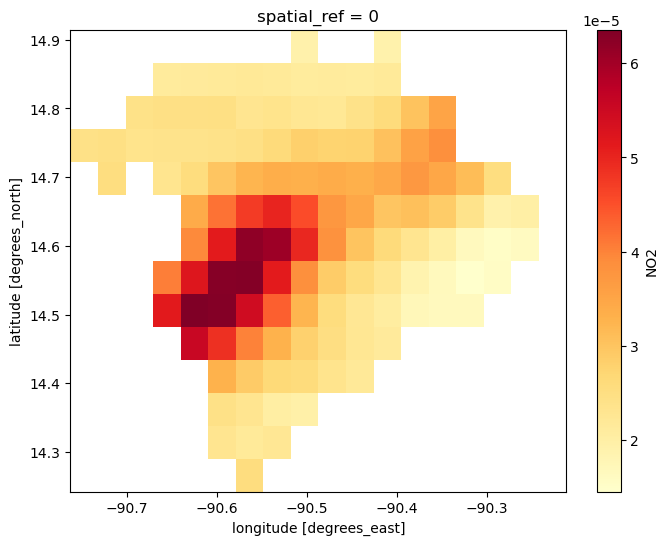

In [5]:
no2_linea_base.plot(cmap="YlOrRd", size=6)

In [7]:
max_no2_val = no2_linea_base.max()
hotspot_no2 = no2_linea_base.where(no2_linea_base == max_no2_val, drop=True)
latitud_no2 = hotspot_no2.y.values[0]
longitud_no2 = hotspot_no2.x.values[0]
concentracion_max_no2 = hotspot_no2.values[0][0]
print("Hotspot Histórico de NO2 (2018-2025)")
print(f"Latitud : {latitud_no2}")
print(f"Longitud: {longitud_no2}")
print(f"Valor   : {concentracion_max_no2} mol/m²")

Hotspot Histórico de NO2 (2018-2025)
Latitud : 14.50644994392857
Longitud: -90.624926285
Valor   : 6.354493962135166e-05 mol/m²
